In [32]:
from wget import download
from os import path, listdir
import pandas as pd
# PARA AUMENTAR EL ANCHO PERMITIDO Y Q NO VEA DATOS CORTADOS
pd.set_option('display.max_colwidth', None)
# PARA DEVOLVER EL ANCHO X DEFAULT 
# pd.set_option('display.max_colwidth', 50)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [33]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [34]:
raw_dataset_results = pd.read_csv("results.csv")
raw_dataset_schema = pd.read_csv("schema.csv")

/tmp/ipykernel_110696/3656956904.py:1: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_dataset_results = pd.read_csv("results.csv")


In [35]:
# 1. Definición de las listas de columnas para cada subgrupo
cols_g1 = ['Country', 'WorkExp', 'ConvertedCompYearly', 'CompTotal', 'Currency', 'Age', 'EdLevel', 'Employment', 'YearsCode']
cols_g2 = ['WorkExp', 'AIAcc', 'JobSat', 'AISent', 'AISelect', 'AIThreat', 'AILearnHow']

# Para el Grupo 3 extraemos dinámicamente todas las de JobSatPoints (del 1 al 15 + TEXT) para evitar hardcodearlas
cols_jobsat = [col for col in raw_dataset_results.columns if col.startswith('JobSatPoints')]
cols_g3 = ['NewRole', 'JobSat'] + cols_jobsat

cols_g4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect', 'RemoteWork', 'DevType', 'Industry', 'ICorPM']
#cols_g5 = ['ToolCountWork', 'LanguageChoice', 'DatabaseChoice', 'PlatformChoice', 'WebframeChoice', 'DevEnvsChoice', 'OpSys']

# 2. Creación de los DataFrames independientes para cada subgrupo
# Usamos .copy() para que cada compañero pueda limpiar nulos o transformar datos sin afectar el dataset original

# Subgrupo 1: Perfil Económico (Para Hipótesis A y HU1)
df_perfil_economico = raw_dataset_results[cols_g1].copy()

# Subgrupo 2: Impacto de la IA (Para Hipótesis B y HB1)
df_impacto_ia = raw_dataset_results[cols_g2].copy()

# Subgrupo 3: Cambio de Rol (Para Hipótesis C)
df_cambio_rol = raw_dataset_results[cols_g3].copy()

# Subgrupo 4: Premio Salarial (Para Hipótesis M4)
df_premio_salarial = raw_dataset_results[cols_g4].copy()

# Subgrupo 5: Fondo Técnico (Ecosistema Tecnológico aislado)
#df_fondo_tecnico = raw_dataset_results[cols_g5].copy()

Transformacion sobre Subgrupo 3: Satisfaccion vs Cambio de Rol:

In [36]:
# 1. Identificamos estrictamente las 15 columnas numéricas de ranking
cols_jobsat_numericas = [
    col for col in df_cambio_rol.columns 
    if col.startswith('JobSatPoints') and not col.endswith('TEXT')
]

# 2. Limpieza general del subgrupo: eliminamos filas de usuarios que no completaron el ranking
df_subgrupo_satisfaccion_limpio = df_cambio_rol.dropna(subset=cols_jobsat_numericas).copy()


Justificacion de limpieza del subgrupo 3 para el informe:
Dado que el dataset crudo (raw_dataset_results) proviene de una plataforma estructurada, no presentó errores de tipado genéricos. Sin embargo, se implementó una limpieza focalizada y obligatoria sobre el tratamiento de Valores Nulos (NaN) mediante el método .dropna(), justificada por las siguientes razones técnicas:

Exigencia matemática de los modelos multivariados: Los algoritmos que aplicaremos para el estudio de este subconjunto (como Análisis de Componentes Principales - PCA, UMAP y Regresión Lineal Múltiple) operan calculando distancias geométricas (ej. distancia euclídea) y matrices de varianzas/covarianzas. Estos algoritmos matemáticos no aceptan valores nulos (NaN) en su ejecución.

Rechazo a la imputación de datos: Tratándose de una encuesta de opinión y satisfacción personal, imputar (rellenar) los valores faltantes con promedios o medianas habría introducido un sesgo artificial severo en el comportamiento de los usuarios, distorsionando la verdadera varianza de los datos. Por lo tanto, la eliminación de las encuestas incompletas fue la acción correctiva más robusta.

Estrategia de eliminación segura (Subsetting): No se aplicó un .dropna() global, ya que columnas de texto libre como JobSatPoints_15_TEXT habrían borrado casi la totalidad de las filas. En su lugar, la limpieza se ejecutó de forma modular: primero se aislaron las variables relacionadas a las encuestas de satisfaccion numericas, y recién entonces se eliminaron las filas con nulos exclusivamente para esas columnas de interés.

------------------------------------------------------
Comienzo de analisis de hipotesis c

Validación de Hipótesis C

¿Están los distintos niveles de satisfacción en los distintos aspectos del trabajo actual relacionados a la consideración de un cambio de rol o de carrera?

Para validar esta hipótesis multivariada, partiremos del Subgrupo 3 (Satisfacción, Retención y Criterio Tecnológico), el cual ya fue saneado de encuestas incompletas en la etapa de limpieza general. Nuestro paso de acondicionamiento será aislar las variables estrictamente necesarias para este cruce y eliminar los valores nulos residuales de nuestra variable dependiente:

    Variable Objetivo (NewRole): Columna categórica (MC) que captura la progresión de intenciones del desarrollador respecto a un cambio laboral en el último año. Se descartarán definitivamente aquellos encuestados que no hayan respondido a esta pregunta, ya que es el vector objetivo (y) indispensable para los modelos de clasificación.

    Variables Predictoras (JobSatPoints_1 a 15): 15 columnas numéricas ordinales (RO) donde el valor 1 indica la máxima prioridad de satisfacción y el 15 la mínima.

    Exclusión de variables incompatibles/redundantes: Filtraremos intencionalmente la opción de texto libre (JobSatPoints_15_TEXT) por no ser procesable matemáticamente para los algoritmos de reducción de dimensionalidad. Asimismo, excluiremos la métrica de satisfacción global (JobSat) para enfocarnos exclusivamente en los distintos aspectos del trabajo, tal como lo exige el enunciado.

In [37]:
cols_sat_float = [
    col for col in df_subgrupo_satisfaccion_limpio.columns 
    if col.startswith('JobSatPoints') and not col.endswith('TEXT')
]

cols_hipotesis_c_utiles = cols_sat_float + ['NewRole']

df_hipotesis_c = df_subgrupo_satisfaccion_limpio[cols_hipotesis_c_utiles].dropna(subset=['NewRole']).copy()

print(f"Total de observaciones listas para el análisis multivariado: {len(df_hipotesis_c)}")
df_hipotesis_c.info()

Total de observaciones listas para el análisis multivariado: 24729
<class 'pandas.DataFrame'>
Index: 24729 entries, 0 to 49188
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   JobSatPoints_1   24729 non-null  float64
 1   JobSatPoints_2   24729 non-null  float64
 2   JobSatPoints_3   24729 non-null  float64
 3   JobSatPoints_4   24729 non-null  float64
 4   JobSatPoints_5   24729 non-null  float64
 5   JobSatPoints_6   24729 non-null  float64
 6   JobSatPoints_7   24729 non-null  float64
 7   JobSatPoints_8   24729 non-null  float64
 8   JobSatPoints_9   24729 non-null  float64
 9   JobSatPoints_10  24729 non-null  float64
 10  JobSatPoints_11  24729 non-null  float64
 11  JobSatPoints_13  24729 non-null  float64
 12  JobSatPoints_14  24729 non-null  float64
 13  JobSatPoints_15  24729 non-null  float64
 14  JobSatPoints_16  24729 non-null  float64
 15  NewRole          24729 non-null  str    
dtypes: floa

Que significan los atributos de satisfaccion:

### Referencia de Atributos de Satisfacción (JobSatPoints)
Para interpretar correctamente los resultados, a continuación se detallan los atributos exactos que los desarrolladores debieron ordenar del 1 (mayor importancia) al 15 (menor importancia):

| Columna | Atributo Evaluado en la Encuesta |
| :--- | :--- |
| **JobSatPoints_1** | Control sobre el nivel de calidad en los proyectos |
| **JobSatPoints_2** | Autonomía y confianza para gestionar tareas propias |
| **JobSatPoints_3** | Colaboración y apoyo del equipo |
| **JobSatPoints_4** | Presencia de mentores expertos |
| **JobSatPoints_5** | Oportunidades para guiar/liderar compañeros junior |
| **JobSatPoints_6** | Desarrollo de experiencia especializada |
| **JobSatPoints_7** | Resolución de problemas del mundo real |
| **JobSatPoints_8** | Estabilidad laboral y crecimiento con el empleador |
| **JobSatPoints_9** | Innovación mediante retos complejos |
| **JobSatPoints_10** | Trabajo con nuevas tecnologías y herramientas |
| **JobSatPoints_11** | Compensación económica y beneficios competitivos |
| **JobSatPoints_13** | Reconocimiento del trabajo por parte de pares |
| **JobSatPoints_14** | Reconocimiento del trabajo por parte de líderes |
| **JobSatPoints_16** | Agradar al jefe/manager (Relación con superiores) |

Análisis de la Variable Objetivo (NewRole)

Antes de aplicar la reducción de dimensionalidad, analizamos la distribución de nuestra variable objetivo. 

Como se observa a continuación, se trata de una variable cualitativa nominal. Si bien las tres primeras opciones sugieren un orden de intención (nula, leve, fuerte), las dos últimas representan acciones concretas y contextuales (cambio voluntario vs. involuntario) que rompen cualquier jerarquía matemática. Por lo tanto, el análisis la tratará como 5 categorías discretas e independientes.

In [38]:
df_hipotesis_c["NewRole"].value_counts()

NewRole
I have neither consider or transitioned into a new career or industry          11460
I have somewhat considered changing my career and/or the industry I work in     7458
I have strongly considered changing my career and/or the industry I work in     3286
I have transitioned into a new career and/or industry voluntarily               2079
I have transitioned into a new career and/or industry involuntarily              446
Name: count, dtype: int64

Paso 1: Ingeniería de Características (Discretización e Inversión de Escala)

Las variables predictoras JobSatPoints presentan un ranking ordinal de 1 a 15, donde 1 representa la máxima prioridad. Para optimizar el rendimiento de los algoritmos de reducción de dimensionalidad (basados en varianza y distancias), aplicaremos una transformación sobre estas columnas fundamentada en dos objetivos:

Reducción de ruido (Binning): Las diferencias minúsculas entre puestos bajos (ej. rankear un atributo en el puesto 13 vs 14) aportan ruido aleatorio en lugar de patrones reales. Agruparemos las respuestas para consolidar la intención del usuario.

Inversión de magnitud: Para que los algoritmos asocien correctamente una mayor intensidad con una mayor importancia matemática, invertiremos la escala original.

Aplicaremos una discretización de 5 niveles jerárquicos:

5 (Muy importante): Puestos 1, 2 y 3

4 (Importante): Puestos 4, 5 y 6

3 (Neutral): Puestos 7, 8 y 9

2 (No tan importante): Puestos 10, 11 y 12

1 (No importante): Puestos 13, 14 y 15

Cabe destacar que, durante la fase exploratoria, se evaluaron empíricamente otras estrategias de agrupamiento (como la condensación en 3 niveles de prioridad o el procesamiento de los rankings en crudo sin transformación). Sin embargo, ninguna de estas alternativas logró mejoras estadísticamente significativas en las métricas de varianza acumulada, reafirmando la decisión de aplicar un esquema de 5 intervalos para balancear la reducción de ruido y la retención de granularidad.

In [39]:
bins = [0, 3, 6, 9, 12, 15] 
labels = [5, 4, 3, 2, 1]    

for col in cols_sat_float:
    df_hipotesis_c[col] = pd.cut(df_hipotesis_c[col], bins=bins, labels=labels, right=True)
    df_hipotesis_c[col] = pd.to_numeric(df_hipotesis_c[col])

df_hipotesis_c.head(1)

,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16,NewRole
0,5,5,4,3,4,2,2,2,5,4,3,1,1,1,3,I have neither consider or transitioned into a new career or industry


Paso 2: Escalado de Datos (Estandarización)

Aunque la discretización previa unificó las 15 variables predictoras bajo una misma amplitud (de 1 a 5), la estandarización (Z-score) sigue siendo un requerimiento matemático estricto antes de aplicar algoritmos basados en la maximización de varianzas y el cálculo de distancias geométricas, como PCA y UMAP. Este proceso centra los datos restándole a cada observación la media de su columna y dividiéndola por su desvío estándar, forzando a que todas las variables tengan una media de 0 y una varianza de 1. De esta forma, se establece una escala uniforme que impide que variables con magnitudes o dispersiones naturalmente mayores dominen el modelo y sesguen el cálculo de la varianza.

Para implementarlo, separaremos la matriz de características (X) de la variable objetivo categórica (y) y aplicaremos la transformación.

In [40]:
from sklearn.preprocessing import StandardScaler

cols_predictoras = [col for col in df_hipotesis_c.columns if col != 'NewRole']
X = df_hipotesis_c[cols_predictoras]
y = df_hipotesis_c['NewRole']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dimensiones de la matriz escalada (X_scaled): {X_scaled.shape}")

Dimensiones de la matriz escalada (X_scaled): (24729, 15)


Paso 3: Análisis de Componentes Principales (PCA) y Visualización

Con los datos estandarizados, aplicaremos Análisis de Componentes Principales (PCA) para reducir la dimensionalidad de las 15 variables de satisfacción a un espacio bidimensional (2 componentes). Nuestro objetivo es evaluar visual y cuantitativamente si existe una separación lineal natural entre los usuarios según su postura frente a un cambio de rol.

Se proyectarán los datos en un gráfico de dispersión, utilizando transparencia para identificar densidades (mitigando el overplotting) y se extraerá el porcentaje de varianza explicada de cada componente para validar matemáticamente la representatividad de la proyección.

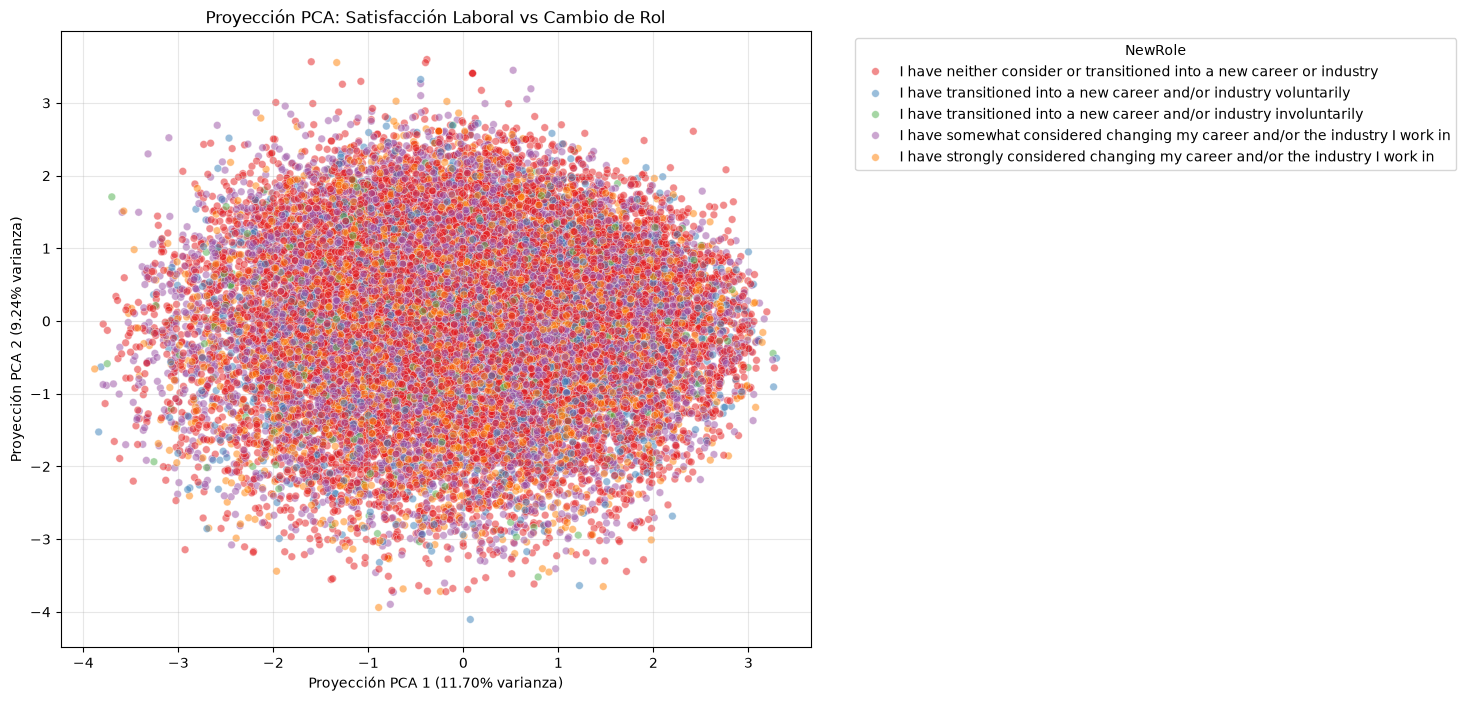

Varianza total explicada en 2D: 20.94%


In [41]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculamos el PCA sobre los datos escalados
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Extraemos la varianza para los ejes
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# 2. Hacemos la figura más ancha de entrada
plt.figure(figsize=(12, 8))

# 3. Graficamos con Seaborn
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1],
    hue=df_hipotesis_c['NewRole'], 
    palette='Set1',
    alpha=0.5,
    s=30
)

plt.grid(True, alpha=0.3)
plt.xlabel(f'Proyección PCA 1 ({var_pc1:.2f}% varianza)')
plt.ylabel(f'Proyección PCA 2 ({var_pc2:.2f}% varianza)')
plt.title('Proyección PCA: Satisfacción Laboral vs Cambio de Rol')

# 4. Posicionamos la leyenda afuera y ajustamos el margen derecho al 75%
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

# Imprimimos el total para la conclusión del informe
print(f"Varianza total explicada en 2D: {(var_pc1 + var_pc2):.2f}%")

Justificación Cuantitativa: Varianza Acumulada

La visualización anterior presenta una fuerte superposición de las categorías. Para fundamentar si esto se debe a la ausencia real de patrones o a una limitación del espacio bidimensional, analizaremos la proporción explicada al escalar hasta 5 componentes principales. Según los criterios teóricos, buscamos retener idealmente más del 80% de la varianza total del dataset original para considerar la representación lineal como robusta.

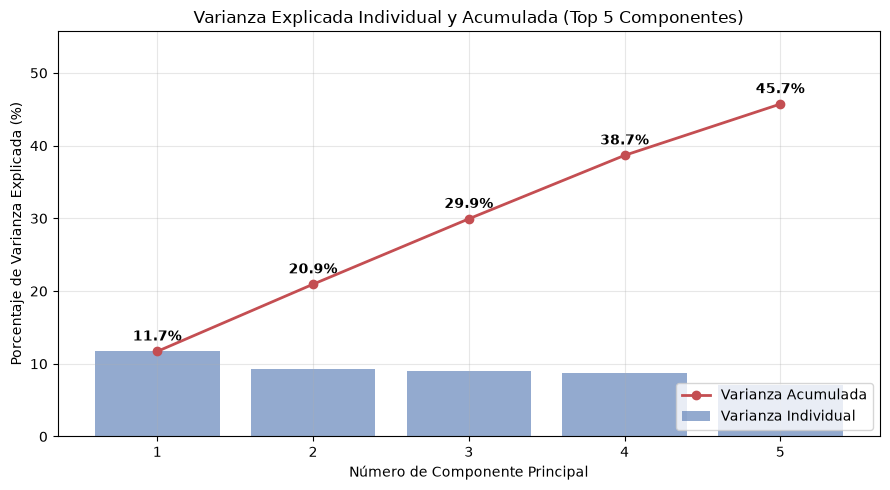

In [42]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Calculamos PCA para 5 componentes sobre los datos escalados
pca_5 = PCA(n_components=5)
pca_5.fit(X_scaled)

# 2. Extraemos la varianza individual y calculamos la acumulada
var_individual = pca_5.explained_variance_ratio_ * 100
var_acumulada = np.cumsum(var_individual)
componentes = np.arange(1, 6)

# 3. Graficamos la integración (Barras para individual, Línea para acumulada)
plt.figure(figsize=(9, 5))
plt.bar(componentes, var_individual, alpha=0.6, color='#4C72B0', label='Varianza Individual')
plt.plot(componentes, var_acumulada, marker='o', color='#C44E52', linewidth=2, label='Varianza Acumulada')

# Agregamos las etiquetas de texto sobre la línea acumulada
for i, txt in enumerate(var_acumulada):
    plt.annotate(f'{txt:.1f}%', (componentes[i], var_acumulada[i] + 1.5), ha='center', fontweight='bold')

plt.xlabel('Número de Componente Principal')
plt.ylabel('Porcentaje de Varianza Explicada (%)')
plt.title('Varianza Explicada Individual y Acumulada (Top 5 Componentes)')
plt.xticks(componentes)
plt.ylim(0, max(var_acumulada) + 10)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Conclusión del Análisis de Componentes Principales (PCA)

La proyección obtenida demuestra gráficamente que no existe una relación lineal simple que logre separar a los encuestados según su intención de cambio de rol. Las distintas categorías de NewRole se distribuyen de manera homogénea y superpuesta (overplotting) a lo largo de todo el plano, sin formar clústeres aislados.

Este comportamiento está fundamentado matemáticamente en la baja varianza explicada. Las dos primeras componentes retienen una porción mínima de la información original de la encuesta. Asimismo, el gráfico de varianza acumulada evidencia que incorporar una tercera, cuarta o quinta componente aporta mejoras puramente marginales, manteniéndonos muy lejos del umbral necesario (>80%) para justificar una representación lineal de los datos.   

Dado que PCA asume relaciones estrictamente lineales en subespacios planos, el modelo no logra representar relaciones complejas entre las características. Al agotar la capacidad de estas transformaciones lineales, pasaremos a explorar la topología de los datos mediante técnicas de reducción no lineal para descartar definitivamente cualquier patrón oculto.   

Paso 4: Reducción de Dimensionalidad No Lineal (UMAP)

Dado que PCA arrojó una baja varianza explicada y no logró separar las clases linealmente, aplicaremos UMAP (Uniform Manifold Approximation and Projection). 

Este algoritmo de manifold learning nos permitirá buscar patrones geométricos complejos y estructuras no lineales subyacentes en las prioridades de satisfacción laboral, proyectándolas nuevamente a 2 dimensiones para evaluar si se forman agrupaciones según la intención de cambio de rol de los desarrolladores.

/home/santirg/Escritorio/Tpe Fundamentos git lucas/TPE-Fundamentos-ciencia-datos/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Dimensiones antes de UMAP: (24729, 15)
Dimensiones después de UMAP: (24729, 2)


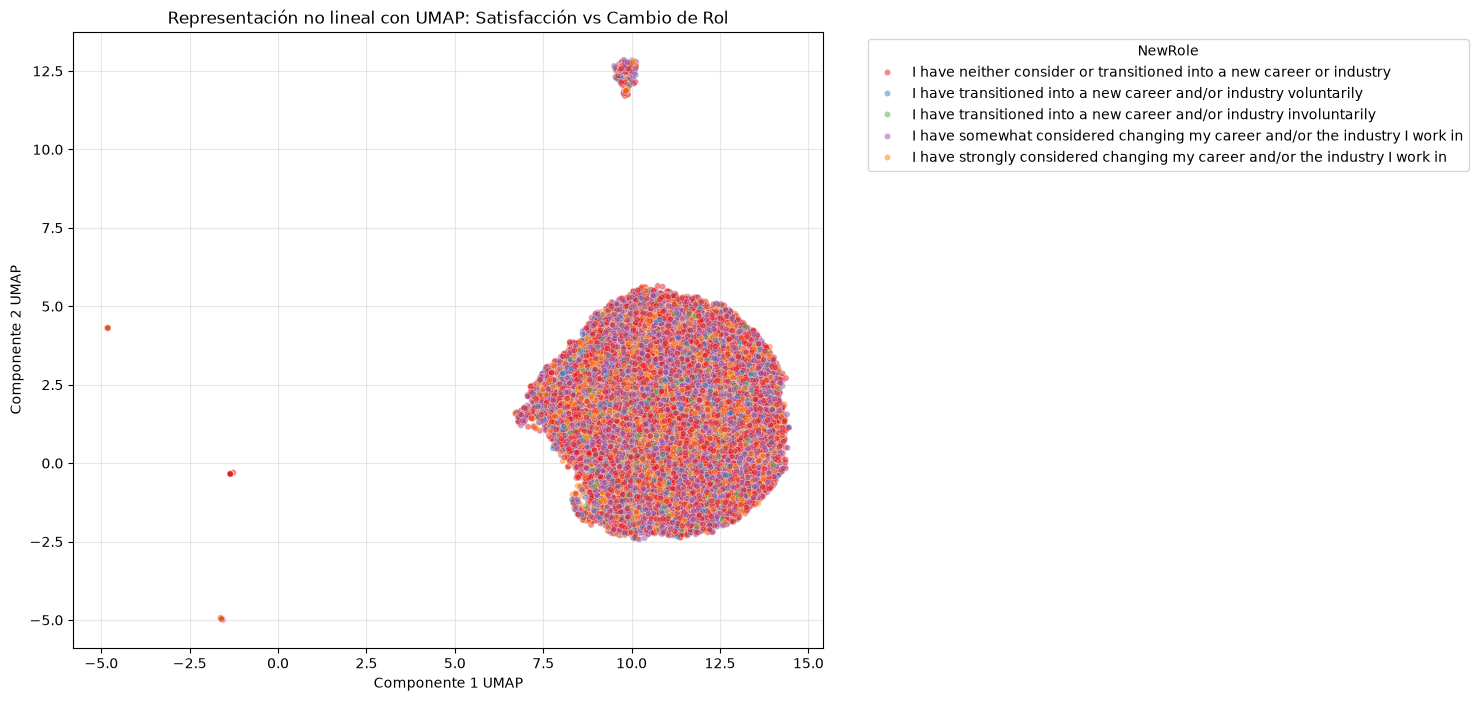

In [43]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt

reductor_umap = UMAP(n_components=2, random_state=42)
X_umap = reductor_umap.fit_transform(X_scaled)

print(f'Dimensiones antes de UMAP: {X_scaled.shape}')
print(f'Dimensiones después de UMAP: {X_umap.shape}')

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_umap[:, 0], 
    y=X_umap[:, 1], 
    hue=df_hipotesis_c["NewRole"], 
    palette='Set1',
    alpha=0.5,
    s=20 
)

plt.grid(True, alpha=0.3)
plt.xlabel('Componente 1 UMAP')
plt.ylabel('Componente 2 UMAP')
plt.title('Representación no lineal con UMAP: Satisfacción vs Cambio de Rol')

plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

Conclusión del Análisis de Reducción No Lineal (UMAP):

Al observar la proyección no lineal, se destacan dos conclusiones fundamentales:


Descubrimiento de subestructuras (Similitud Local): UMAP logró identificar agrupaciones aisladas ("islas") fuera de la nube principal de datos. Esto indica la existencia de una minoría de encuestados que comparten un perfil de satisfacción altamente específico y similar entre sí, distanciado del patrón de respuestas de la mayoría.  


Independencia de la variable objetivo (NewRole): Al analizar la distribución de la variable categórica en el gráfico, observamos que las clases siguen estando mezcladas de forma heterogénea en la nube principal. Más importante aún, incluso dentro del clúster aislado (la "isla"), conviven usuarios con decisiones de carrera diametralmente opuestas (los 5 colores se encuentran presentes).

Estos resultados nos permiten descartar que la superposición observada en PCA se debiera exclusivamente a la presencia de estructuras complejas no lineales en el espacio de alta dimensión.

Paso 5: Validación Predictiva mediante Regresión Logística Multinomial

Si bien las técnicas de reducción de dimensionalidad (PCA y UMAP) demostraron visualmente la ausencia de clústeres separables, procederemos a validar esta conclusión de manera cuantitativa utilizando un modelo de Machine Learning de clasificación supervisada.

Implementaremos una Regresión Logística Multinomial utilizando las 15 variables de satisfacción como predictoras. Nuestro objetivo es evaluar si el algoritmo es capaz de aprender algún patrón matemático subyacente que le permita predecir correctamente la categoría de NewRole a la que pertenece un desarrollador. Si, como sugieren los gráficos anteriores, no existe correlación entre las prioridades y la decisión de cambio, el modelo arrojará un Accuracy (Exactitud) deficiente, confirmando el rechazo de la hipótesis de forma irrefutable.

Exactitud (Accuracy) del modelo: 0.4634 (46.34%)


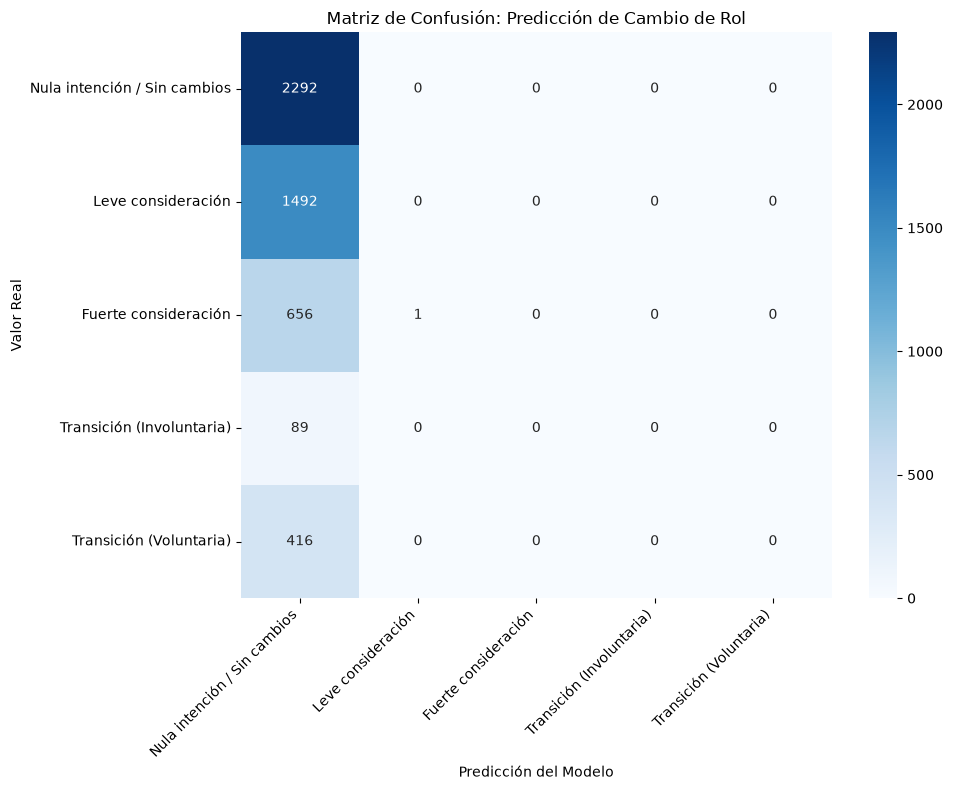

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_logistico.fit(X_train, y_train)

y_pred = modelo_logistico.predict(X_test)

exactitud = accuracy_score(y_test, y_pred)
matriz_conf = confusion_matrix(y_test, y_pred)

print(f"Exactitud (Accuracy) del modelo: {exactitud:.4f} ({exactitud*100:.2f}%)")

mapeo_clases_cortas = {
    'I have neither consider or transitioned into a new career or industry': 'Nula intención / Sin cambios',
    'I have somewhat considered changing my career and/or the industry I work in': 'Leve consideración',
    'I have strongly considered changing my career and/or the industry I work in': 'Fuerte consideración',
    'I have transitioned into a new career and/or industry voluntarily': 'Transición (Voluntaria)',
    'I have transitioned into a new career and/or industry involuntarily': 'Transición (Involuntaria)'
}

etiquetas_cortas = [mapeo_clases_cortas[clase] for clase in modelo_logistico.classes_]

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_conf, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=etiquetas_cortas,
    yticklabels=etiquetas_cortas
)

plt.title('Matriz de Confusión: Predicción de Cambio de Rol')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Análisis y Discusión de Resultados (Hipótesis C)

1. Hipótesis rechazada y por quéRechazamos formalmente la Hipótesis C. La premisa inicial suponía que las prioridades que un desarrollador le asigna a distintos factores de su trabajo actual (salario, autonomía, equipo, etc.) poseían poder predictivo sobre su decisión de cambiar de carrera o rol. Sin embargo, tras validar la ausencia de patrones en PCA y UMAP, el modelo de Regresión Logística Multinomial colapsó estructuralmente. Arrojó una exactitud (Accuracy) del 46.34%, un valor que coincide de forma exacta con la proporción de la clase mayoritaria ("Nula intención / Sin cambios", con 11.460 sobre 24.729 encuestados). Esto demuestra matemáticamente que, ante la falta de un patrón real, el algoritmo optó por una heurística ingenua (predecir a todos en la clase mayoritaria), confirmando que las 15 variables de satisfacción carecen de capacidad predictiva para anticipar un cambio laboral.

2. Discusión de los resultados y justificación del rechazo

¿Por qué podría pasar esto en el mercado real?

La brecha entre la "Opinión" y la "Acción": Este fenómeno contraintuitivo se explica por la diferencia entre estar insatisfecho y poder hacer algo al respecto. Un desarrollador puede rankear el "Salario" como su máxima prioridad y estar muy descontento con él, pero la acción concreta de transicionar de rol requiere un costo de energía alto, tiempo libre para hacer entrevistas técnicas y tolerancia al riesgo. La insatisfacción genera la queja, pero no garantiza la renuncia inmediata.

Variables Omitidas (Contexto Macroeconómico y Demográfico): Como no se incluyeron en este cruce variables externas, el modelo fracasó. La decisión de cambiar de trabajo en la industria tecnológica está hoy fuertemente impulsada por factores externos: la edad del encuestado, sus cargas familiares, o el estado macroeconómico global (como las recientes olas de despidos masivos o layoffs en el sector Tech), las cuales congelan la movilidad laboral independientemente de qué tan prioritaria sea la autonomía o el liderazgo para el empleado.

Conclusión de negocio: Rechazamos la hipótesis porque anticipar la fuga de talento requiere ir mucho más allá del "clima laboral". Para los departamentos de Recursos Humanos, este modelo demuestra que las tradicionales "encuestas de satisfacción internas" son insuficientes para predecir renuncias. Retener talento exige monitorear el contexto económico, el seniority y las oportunidades reales que ese empleado tiene en el mercado externo, no solo ordenando qué le molesta de su oficina actual.